# Proyecto 2 – Mejora de la SNR de una IMU con filtros FIR e IIR
**Equipo 2** · Procesamiento Digital de Señales – Teoría · 2026-2 · Universidad Militar Nueva Granada

Este notebook lee `R1.csv`, `R2.csv` y `R3.csv`, calcula $P_s$, $P_n$, la SNR de entrada y de salida y $\Delta$SNR para un FIR de orden 20 (ventana de Hamming) y un IIR Butterworth de orden 2, ambos con corte de 5 Hz, y genera `tabla_resultados.csv`, `tabla_cortes_ordenes.csv` y las figuras `fig1` a `fig4`.

**Uso:** Entorno de ejecución → *Reiniciar y ejecutar todo*.

## 1. Vista previa de los datos

In [8]:
import pandas as pd
import numpy as np

for nombre in ["R1", "R2", "R3"]:
    df = pd.read_csv(nombre + ".csv")
    print(nombre, "->", len(df), "filas | columnas:", list(df.columns))
    print(df.head(3))
    print()
# Frecuencia de muestreo REAL, medida desde los timestamps (no solo la declarada)
print("VERIFICACIÓN DEL MUESTREO")
for nombre in ["R1", "R2", "R3"]:
    df = pd.read_csv(nombre + ".csv")
    ts = df["timestamp_us"].values
    dt = np.diff(ts) / 1e6
    print(f"{nombre}: {len(df)} muestras | duración {(ts[-1]-ts[0])/1e6:.2f} s | fs declarada {df['fs_hz'].iloc[0]:.2f} Hz"
          f" | fs real {1/dt.mean():.2f} Hz | dt mín/máx {dt.min()*1e3:.2f}/{dt.max()*1e3:.2f} ms")


R1 -> 2000 filas | columnas: ['timestamp_us', 'az_crudo', 'unidad', 'fs_hz', 'pwm_pct']
   timestamp_us  az_crudo             unidad  fs_hz  pwm_pct
0           178     14808  cuentas(16384=1g)  100.0        0
1         10019     14848  cuentas(16384=1g)  100.0        0
2         20012     14876  cuentas(16384=1g)  100.0        0

R2 -> 2000 filas | columnas: ['timestamp_us', 'az_crudo', 'unidad', 'fs_hz', 'pwm_pct']
   timestamp_us  az_crudo             unidad  fs_hz  pwm_pct
0           104     14800  cuentas(16384=1g)  100.0       60
1         10018     14700  cuentas(16384=1g)  100.0       60
2         20019     14780  cuentas(16384=1g)  100.0       60

R3 -> 2000 filas | columnas: ['timestamp_us', 'az_crudo', 'unidad', 'fs_hz', 'pwm_pct']
   timestamp_us  az_crudo             unidad  fs_hz  pwm_pct
0           104     14812  cuentas(16384=1g)  100.0      100
1         10015     14608  cuentas(16384=1g)  100.0      100
2         20028     14896  cuentas(16384=1g)  100.0      100

V

## 2. Filtros, SNR, retardo, tiempos y figuras 1 a 3
$P_s=\overline{x}^2$, $P_n=\overline{(x-\overline{x})^2}$, SNR $=10\log_{10}(P_s/P_n)$. Se descarta el primer segundo (100 muestras) de la entrada y de las salidas.

`SNR_entrada_dB` usa las mismas muestras que las salidas filtradas (sin el primer segundo), para comparar de forma justa. `SNR_entrada_2000muestras_dB` es la SNR del registro crudo completo.

fs = 100.0 Hz | corte = 5 Hz
FIR b: [0.      0.00133 0.00465 0.01175 0.02378 0.04072 0.06116 0.0824  0.10108
 0.1139  0.11846 0.1139  0.10108 0.0824  0.06116 0.04072 0.02378 0.01175
 0.00465 0.00133 0.     ]
IIR b: [0.02008 0.04017 0.02008] | a: [ 1.      -1.56102  0.64135]
Polos IIR: [0.7805+0.1793j 0.7805-0.1793j] | modulos: [0.8008 0.8008]
¿Todos los polos dentro del círculo unitario? True
Ecuacion IIR: y[n] = 0.02008 x[n] + 0.04017 x[n-1] + 0.02008 x[n-2] + 1.56102 y[n-1] - 0.64135 y[n-2]
Ecuacion FIR: y[n] = suma_{k=0..20} h[k] x[n-k]  (h simetrico)

                                                        0  \
Registro                                               R1   
Ps                                              219750352   
Pn                                                 7841.5   
SNR_entrada_dB                                      44.48   
SNR_entrada_2000muestras_dB                         44.51   
SNR_FIR_dB                                          54.34   
dSNR_FIR_dB

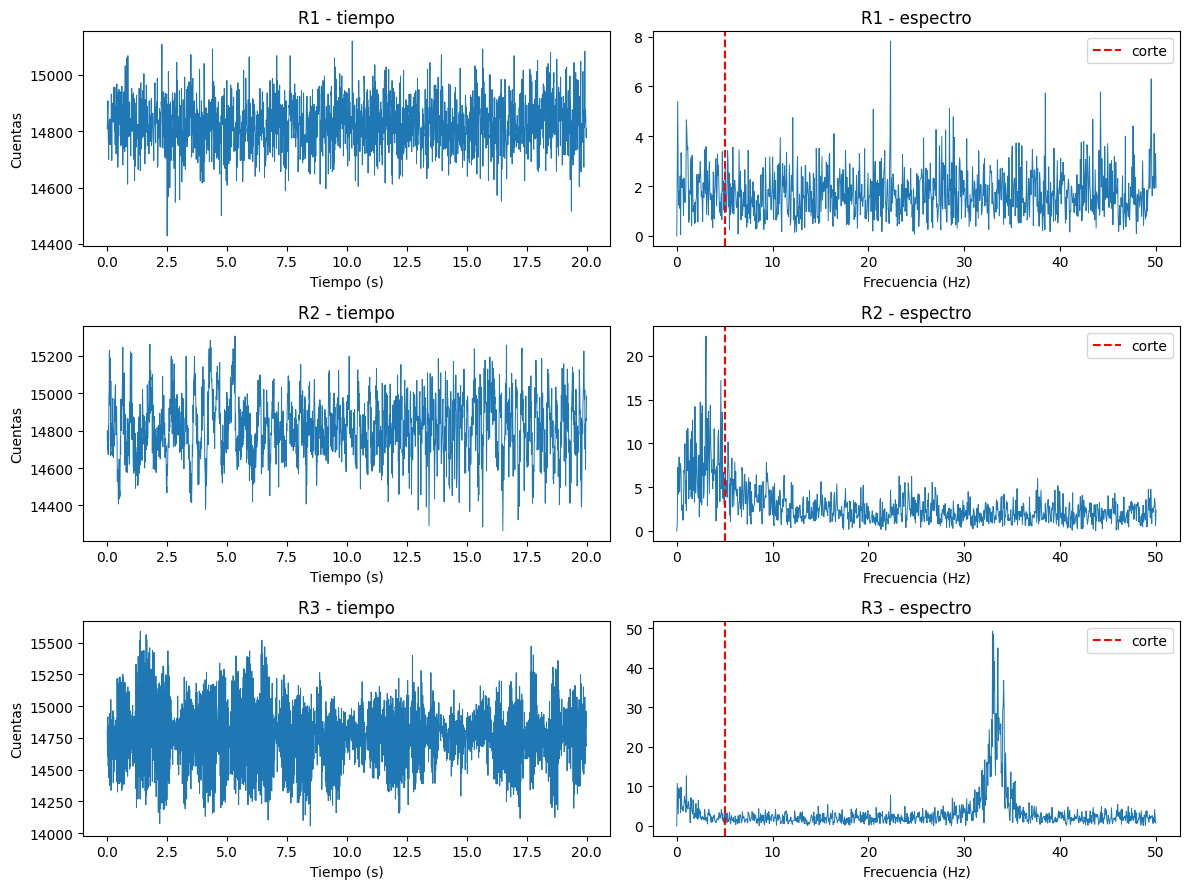

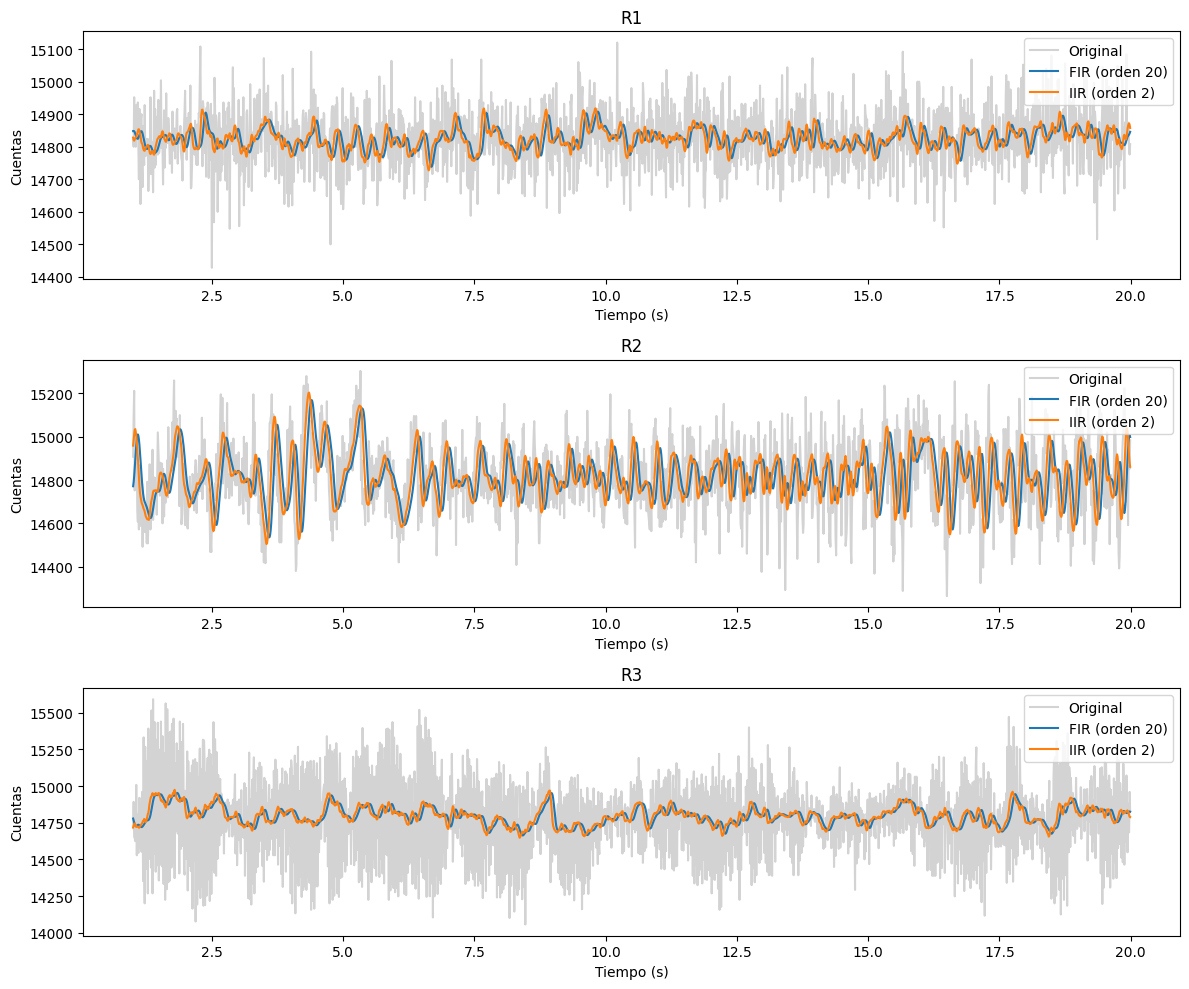

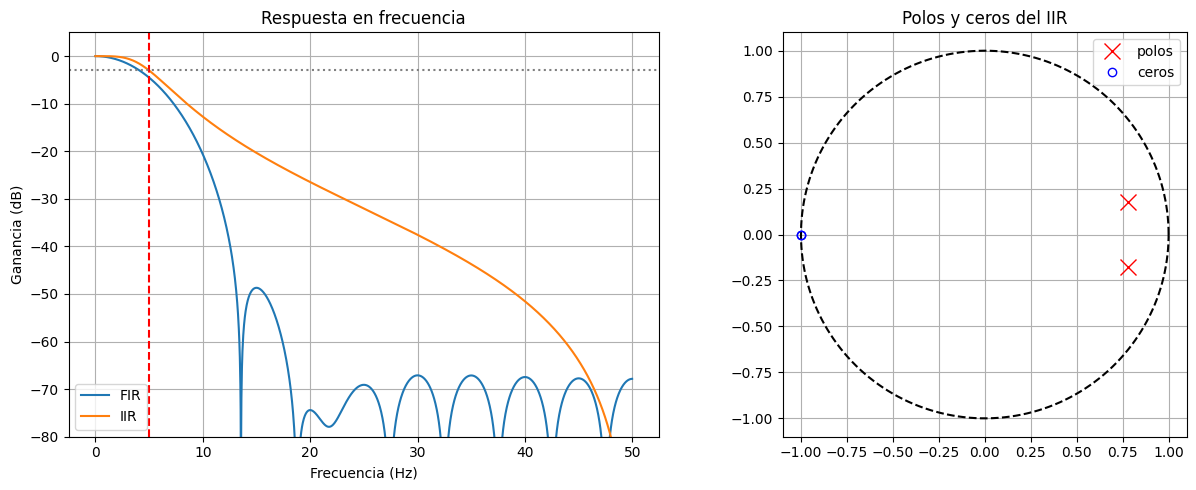

In [9]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from scipy import signal

# ---------- PARÁMETROS ----------
REGISTROS = ["R1", "R2", "R3"]
FC = 5            # frecuencia de corte (Hz), igual para FIR e IIR
ORDEN_FIR = 20
ORDEN_IIR = 2
DESCARTE_S = 1    # se elimina el primer segundo de las salidas
# --------------------------------

def snr_db(x):
    Ps = np.mean(x) ** 2
    Pn = np.mean((x - np.mean(x)) ** 2)
    return 10 * np.log10(Ps / Pn), Ps, Pn

def retardo_obs(y, ref, d):
    y = y[d:] - np.mean(y[d:])
    r = ref[d:] - np.mean(ref[d:])
    c = np.correlate(y, r, mode="full")
    return int(np.arange(-len(r) + 1, len(r))[np.argmax(c)])

# Filtros
fs = float(pd.read_csv("R1.csv")["fs_hz"].iloc[0])
d = int(DESCARTE_S * fs)
b_fir = signal.firwin(ORDEN_FIR + 1, FC, window="hamming", fs=fs)
b_iir, a_iir = signal.butter(ORDEN_IIR, FC, btype="low", fs=fs)
polos = np.roots(a_iir)

print("fs =", fs, "Hz | corte =", FC, "Hz")
print("FIR b:", np.round(b_fir, 5))
print("IIR b:", np.round(b_iir, 5), "| a:", np.round(a_iir, 5))
print("Polos IIR:", np.round(polos, 4), "| modulos:", np.round(np.abs(polos), 4))
print("¿Todos los polos dentro del círculo unitario?", bool(np.all(np.abs(polos) < 1)))
print(f"Ecuacion IIR: y[n] = {b_iir[0]:.5f} x[n] + {b_iir[1]:.5f} x[n-1] + {b_iir[2]:.5f} x[n-2] + {-a_iir[1]:.5f} y[n-1] - {a_iir[2]:.5f} y[n-2]")
print("Ecuacion FIR: y[n] = suma_{k=0..20} h[k] x[n-k]  (h simetrico)\n")

filas, datos = [], {}
for nom in REGISTROS:
    x = pd.read_csv(nom + ".csv")["az_crudo"].values.astype(float)

    tf = []
    for _ in range(200):
        t0 = time.perf_counter(); yf = signal.lfilter(b_fir, [1.0], x); tf.append(time.perf_counter() - t0)
    ti = []
    for _ in range(200):
        t0 = time.perf_counter(); yi = signal.lfilter(b_iir, a_iir, x); ti.append(time.perf_counter() - t0)

    ref = signal.filtfilt(b_iir, a_iir, x - np.mean(x))
    df_ = retardo_obs(yf - np.mean(x), ref, d)
    di_ = retardo_obs(yi - np.mean(x), ref, d)

    xc, yfc, yic = x[d:], yf[d:], yi[d:]
    s_in, Ps, Pn = snr_db(xc)
    s_f = snr_db(yfc)[0]
    s_i = snr_db(yic)[0]

    filas.append({"Registro": nom, "Ps": round(Ps), "Pn": round(Pn, 1),
                  "SNR_entrada_dB": round(s_in, 2),
                  "SNR_entrada_2000muestras_dB": round(snr_db(x)[0], 2),
                  "SNR_FIR_dB": round(s_f, 2), "dSNR_FIR_dB": round(s_f - s_in, 2),
                  "SNR_IIR_dB": round(s_i, 2), "dSNR_IIR_dB": round(s_i - s_in, 2),
                  "cambio_media_FIR": round(np.mean(yfc) - np.mean(xc), 2),
                  "cambio_media_IIR": round(np.mean(yic) - np.mean(xc), 2),
                  "orden_FIR": ORDEN_FIR, "orden_IIR": ORDEN_IIR,
                  "retardo_FIR_muestras": df_, "retardo_IIR_muestras": di_,
                  "tiempo_FIR_us": round(np.median(tf) * 1e6, 1),
                  "tiempo_IIR_us": round(np.median(ti) * 1e6, 1),
                  "estab_FIR": "estable (sin realimentacion)",
                  "estab_IIR": ("estable (polos %.2f < 1)" % np.abs(polos).max()) if np.all(np.abs(polos) < 1)
                              else ("INESTABLE (polo %.2f >= 1)" % np.abs(polos).max())})
    datos[nom] = (x, yf, yi)

tabla = pd.DataFrame(filas)
tabla.to_csv("tabla_resultados.csv", index=False)
print(tabla.T)

# ---------- GRÁFICAS (se guardan como PNG) ----------
# 1. Tiempo y espectro de la señal cruda
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
for k, nom in enumerate(REGISTROS):
    x = datos[nom][0]; t = np.arange(len(x)) / fs
    ax[k, 0].plot(t, x, lw=0.7); ax[k, 0].set_title(nom + " - tiempo")
    ax[k, 0].set_xlabel("Tiempo (s)"); ax[k, 0].set_ylabel("Cuentas")
    xc = x - np.mean(x)
    ax[k, 1].plot(np.fft.rfftfreq(len(xc), 1/fs), np.abs(np.fft.rfft(xc)) / len(xc), lw=0.7)
    ax[k, 1].axvline(FC, color="r", ls="--", label="corte")
    ax[k, 1].set_title(nom + " - espectro"); ax[k, 1].set_xlabel("Frecuencia (Hz)"); ax[k, 1].legend()
plt.tight_layout(); plt.savefig("fig1_senales_espectro.png", dpi=150); plt.show()

# 2. Original vs filtradas
fig, ax = plt.subplots(3, 1, figsize=(12, 10))
for k, nom in enumerate(REGISTROS):
    x, yf, yi = datos[nom]; t = np.arange(len(x)) / fs
    ax[k].plot(t[d:], x[d:], color="lightgray", label="Original")
    ax[k].plot(t[d:], yf[d:], label="FIR (orden 20)")
    ax[k].plot(t[d:], yi[d:], label="IIR (orden 2)")
    ax[k].set_title(nom); ax[k].set_xlabel("Tiempo (s)"); ax[k].set_ylabel("Cuentas"); ax[k].legend(loc="upper right")
plt.tight_layout(); plt.savefig("fig2_filtradas.png", dpi=150); plt.show()

# 3. Respuesta en frecuencia y polos
w, hf = signal.freqz(b_fir, [1.0], worN=2048, fs=fs)
w, hi = signal.freqz(b_iir, a_iir, worN=2048, fs=fs)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(w, 20*np.log10(np.abs(hf) + 1e-12), label="FIR")
ax[0].plot(w, 20*np.log10(np.abs(hi) + 1e-12), label="IIR")
ax[0].axvline(FC, color="r", ls="--"); ax[0].axhline(-3, color="gray", ls=":")
ax[0].set_ylim(-80, 5); ax[0].set_xlabel("Frecuencia (Hz)"); ax[0].set_ylabel("Ganancia (dB)")
ax[0].set_title("Respuesta en frecuencia"); ax[0].legend(); ax[0].grid(True)
ang = np.linspace(0, 2*np.pi, 400)
ax[1].plot(np.cos(ang), np.sin(ang), "k--")
ax[1].plot(polos.real, polos.imag, "rx", ms=12, label="polos")
ceros = np.roots(b_iir)
ax[1].plot(ceros.real, ceros.imag, "bo", fillstyle="none", label="ceros")
ax[1].set_aspect("equal"); ax[1].set_title("Polos y ceros del IIR"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig("fig3_respuesta_polos.png", dpi=150); plt.show()

## 3. Retardo teórico y ganancias

In [10]:
# ---------- Retardo teórico y ganancias (respaldan el informe) ----------
gd_iir = signal.group_delay((b_iir, a_iir), w=[0.05], fs=fs)[1][0]
print("Retardo teórico FIR = %.1f muestras = %.3f s" % (ORDEN_FIR / 2, ORDEN_FIR / 2 / fs))
print("Retardo teórico IIR (continua) = %.2f muestras = %.3f s" % (gd_iir, gd_iir / fs))

def ganancia_db(b, a, f):
    return 20 * np.log10(abs(signal.freqz(b, a, worN=[f], fs=fs)[1][0]))

for f in (5, 33):
    print("Ganancia a %d Hz | FIR: %.1f dB | IIR: %.1f dB" % (f, ganancia_db(b_fir, [1.0], f), ganancia_db(b_iir, a_iir, f)))

w_, h_ = signal.freqz(b_fir, [1.0], worN=4096, fs=fs)
f45 = w_[np.where(20 * np.log10(np.abs(h_) + 1e-12) > -45)[0].max() + 1]
print("El FIR queda por debajo de -45 dB desde %.1f Hz" % f45)

Retardo teórico FIR = 10.0 muestras = 0.100 s
Retardo teórico IIR (continua) = 4.46 muestras = 0.045 s
Ganancia a 5 Hz | FIR: -4.5 dB | IIR: -3.0 dB
Ganancia a 33 Hz | FIR: -77.4 dB | IIR: -41.1 dB
El FIR queda por debajo de -45 dB desde 12.9 Hz


## 4. Barrido de corte y orden (tabla y figura 4)

barrido filtro  orden  fc_Hz  retardo_s  dSNR_R1  dSNR_R2  dSNR_R3  max_cambio_media
  corte    FIR     20      1       0.10    10.69     5.20    13.52              0.30
  corte    IIR      2      1       0.23    12.25    11.17    15.46              0.63
  corte    FIR     20      2       0.10    10.59     5.08    13.49              0.30
  corte    IIR      2      2       0.11    12.14     7.57    14.04              0.32
  corte    FIR     20      3       0.10    10.42     4.88    13.42              0.30
  corte    IIR      2      3       0.07    10.77     5.38    13.43              0.25
  corte    FIR     20      5       0.10     9.86     4.27    13.21              0.31
  corte    IIR      2      5       0.04     8.99     3.36    12.82              0.44
  corte    FIR     20      8       0.10     8.63     3.10    12.71              0.33
  corte    IIR      2      8       0.03     7.42     2.31    12.18              0.33
  corte    FIR     20     10       0.10     7.75     2.44    12.3

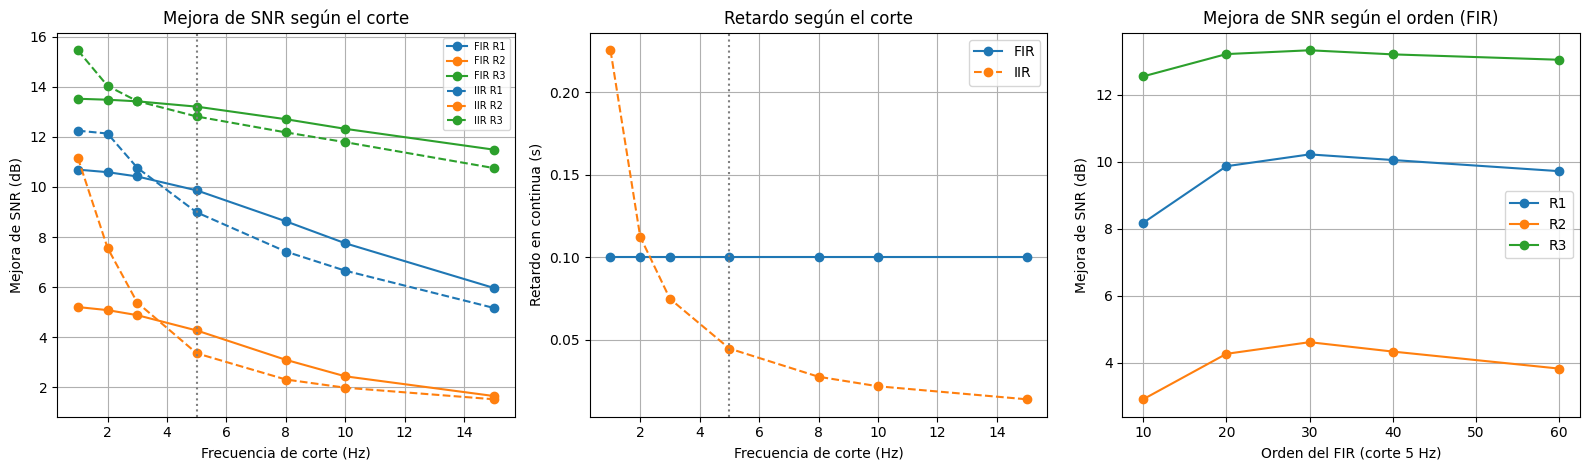

In [11]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

fs, d = 100, 100
REG = ["R1", "R2", "R3"]
X = {r: pd.read_csv(r + ".csv")["az_crudo"].values.astype(float) for r in REG}

def snr_db(x):
    return 10*np.log10(np.mean(x)**2 / np.mean((x - np.mean(x))**2))

def evaluar(b, a):
    ds, dm = [], []
    for r in REG:
        x = X[r]
        y = signal.lfilter(b, a, x)
        ds.append(snr_db(y[d:]) - snr_db(x[d:]))
        dm.append(np.mean(y[d:]) - np.mean(x[d:]))
    ret = signal.group_delay((b, a), w=[0.05], fs=fs)[1][0] / fs
    return ds, max(abs(m) for m in dm), ret

filas = []
def agregar(barrido, fam, orden, fc):
    if fam == "FIR":
        b, a = signal.firwin(orden + 1, fc, window="hamming", fs=fs), [1.0]
    else:
        b, a = signal.butter(orden, fc, btype="low", fs=fs)
    ds, dm, ret = evaluar(b, a)
    filas.append({"barrido": barrido, "filtro": fam, "orden": orden, "fc_Hz": fc,
                  "retardo_s": ret, "dSNR_R1": ds[0], "dSNR_R2": ds[1],
                  "dSNR_R3": ds[2], "max_cambio_media": dm})

# Barrido 1: frecuencia de corte (FIR orden 20 e IIR orden 2)
for fc in [1, 2, 3, 5, 8, 10, 15]:
    agregar("corte", "FIR", 20, fc)
    agregar("corte", "IIR", 2, fc)

# Barrido 2: orden, con corte fijo en 5 Hz
for o in [10, 20, 30, 40, 60]:
    agregar("orden", "FIR", o, 5)
for o in [1, 2, 3, 4]:
    agregar("orden", "IIR", o, 5)

t = pd.DataFrame(filas)
t.round(3).to_csv("tabla_cortes_ordenes.csv", index=False)
print(t.round(2).to_string(index=False))

# Gráfica
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
colores = {"R1": "C0", "R2": "C1", "R3": "C2"}

c = t[t.barrido == "corte"]
for fam, ls in [("FIR", "-"), ("IIR", "--")]:
    s = c[c.filtro == fam]
    for r in REG:
        ax[0].plot(s.fc_Hz, s["dSNR_" + r], ls, color=colores[r], marker="o", label=fam + " " + r)
    ax[1].plot(s.fc_Hz, s.retardo_s, ls, marker="o", label=fam)
ax[0].axvline(5, color="gray", ls=":")
ax[0].set_xlabel("Frecuencia de corte (Hz)"); ax[0].set_ylabel("Mejora de SNR (dB)")
ax[0].set_title("Mejora de SNR según el corte"); ax[0].legend(fontsize=7); ax[0].grid(True)
ax[1].axvline(5, color="gray", ls=":")
ax[1].set_xlabel("Frecuencia de corte (Hz)"); ax[1].set_ylabel("Retardo en continua (s)")
ax[1].set_title("Retardo según el corte"); ax[1].legend(); ax[1].grid(True)

o = t[(t.barrido == "orden") & (t.filtro == "FIR")]
for r in REG:
    ax[2].plot(o.orden, o["dSNR_" + r], marker="o", color=colores[r], label=r)
ax[2].set_xlabel("Orden del FIR (corte 5 Hz)"); ax[2].set_ylabel("Mejora de SNR (dB)")
ax[2].set_title("Mejora de SNR según el orden (FIR)"); ax[2].legend(); ax[2].grid(True)

plt.tight_layout()
plt.savefig("fig4_cortes_ordenes.png", dpi=150)
plt.show()